# Phishing URL Detection – Neural Network + URL Checker

**Why the old notebook couldn't check a URL:** it used columns like `ranking`, `mld_res`, `jaccard_RR` which are computed from search-engine and page-content lookups – you cannot get them from a URL someone types in. This version builds the features **from the URL text itself**, so any URL can be checked.

Run the cells from top to bottom. The URL checker (with a text box) is at the very end.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import math, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from urllib.parse import urlparse

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (confusion_matrix, precision_score, recall_score,
                             f1_score, accuracy_score, classification_report)

## 1. Load the dataset

Put `urlset.csv` in the same folder as this notebook. (In Google Colab: click the folder icon on the left and upload it, or run the optional cell below.)

In [2]:
# OPTIONAL – only for Google Colab: uncomment the next 2 lines to upload urlset.csv
# from google.colab import files
# files.upload()

In [3]:
df = pd.read_csv("urlset.csv", encoding="latin1", low_memory=False, on_bad_lines="skip")
df["label"] = pd.to_numeric(df["label"], errors="coerce")
df = df.dropna(subset=["domain", "label"])
df["label"] = df["label"].astype(int)      # 1 = phishing, 0 = legitimate

print("Dataset shape:", df.shape)
print(df["label"].value_counts())
df[["domain", "label"]].head()

Dataset shape: (95913, 14)
label
0    48009
1    47904
Name: count, dtype: int64


,domain,label
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,1
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,1
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,1
3,mail.printakid.com/www.online.americanexpress....,1
4,thewhiskeydregs.com/wp-content/themes/widescre...,1


## 2. Turn a URL into numbers (feature extraction)

This function is the key fix. It works on **any** URL (also used later by the checker).

In [4]:
SUSPICIOUS_WORDS = ["login", "signin", "secure", "verify", "account", "update", "bank",
                    "paypal", "confirm", "password", "wallet", "support", "billing",
                    "webscr", "ebay", "cmd", "security", "banking", "validate", "suspend"]
SUSPICIOUS_TLDS = {"tk", "ml", "ga", "cf", "gq", "xyz", "top", "click", "work", "zip",
                   "info", "biz", "ru", "cn", "pw", "cc", "su"}
BRANDS = ["paypal", "ebay", "apple", "google", "microsoft", "amazon", "facebook",
          "netflix", "bank", "chase", "wellsfargo", "dropbox", "linkedin", "yahoo"]
SHORTENERS = {"bit.ly", "tinyurl.com", "goo.gl", "t.co", "ow.ly", "is.gd", "buff.ly"}
IP_RE = re.compile(r"^\d{1,3}(\.\d{1,3}){3}$")

FEATURE_NAMES = [
    "url_length", "host_length", "path_length", "query_length", "num_dots",
    "num_hyphens", "num_underscores", "num_digits", "digit_ratio", "num_slashes",
    "num_subdomains", "tld_length", "has_ip", "has_at_symbol", "has_punycode",
    "host_entropy", "url_entropy", "longest_label", "suspicious_words",
    "suspicious_tld", "brand_in_subdomain_or_path", "brand_not_main_domain",
    "num_params", "special_chars", "max_digit_run", "is_shortener", "has_port",
    "double_slash_in_path", "host_hyphens", "path_depth",
]

def parse(url):
    """Return (host, path, query, port, cleaned_url) – scheme and www removed."""
    url = str(url).strip().strip("'\"").strip()
    full = url if "://" in url else "http://" + url
    p = urlparse(full)
    host = (p.hostname or "").lower()
    if host.startswith("www."):
        host = host[4:]
    try:
        port = p.port
    except ValueError:
        port = None
    return host, p.path or "", p.query or "", port, url.lower()

def entropy(s):
    if not s:
        return 0.0
    return -sum((s.count(c) / len(s)) * math.log2(s.count(c) / len(s)) for c in set(s))

def extract_features(url):
    host, path, query, port, raw = parse(url)
    labels = [l for l in host.split(".") if l]
    tld = labels[-1] if labels else ""
    main = labels[-2] if len(labels) >= 2 else host
    sub = ".".join(labels[:-2])
    full = raw.split("://", 1)[-1]
    full = full[4:] if full.startswith("www.") else full
    n = max(len(full), 1)
    digits = sum(c.isdigit() for c in full)
    runs = re.findall(r"\d+", full)
    tail = (sub + path + query).lower()
    brand_hit = int(any(b in tail for b in BRANDS))
    brand_off = int(any(b in host for b in BRANDS) and not any(main.startswith(b) for b in BRANDS))
    return [
        len(full), len(host), len(path), len(query), full.count("."),
        full.count("-"), full.count("_"), digits, digits / n, full.count("/"),
        max(len(labels) - 2, 0), len(tld), int(bool(IP_RE.match(host))), int("@" in full),
        int("xn--" in host), entropy(host), entropy(full),
        max((len(l) for l in labels), default=0),
        sum(w in full for w in SUSPICIOUS_WORDS), int(tld in SUSPICIOUS_TLDS),
        brand_hit, brand_off, query.count("="), sum(full.count(c) for c in "%&=~$!*"),
        max((len(r) for r in runs), default=0), int(host in SHORTENERS), int(port is not None),
        int("//" in path), host.count("-"), path.count("/"),
    ]

def extract_matrix(urls):
    return np.array([extract_features(u) for u in urls], dtype="float32")

# quick test
print(dict(zip(FEATURE_NAMES, extract_features("http://paypal.com.secure-login.tk/webscr?cmd=login"))))

{'url_length': 43, 'host_length': 26, 'path_length': 7, 'query_length': 9, 'num_dots': 3, 'num_hyphens': 1, 'num_underscores': 0, 'num_digits': 0, 'digit_ratio': 0.0, 'num_slashes': 1, 'num_subdomains': 2, 'tld_length': 2, 'has_ip': 0, 'has_at_symbol': 0, 'has_punycode': 0, 'host_entropy': 4.056020968057882, 'url_entropy': 4.425810103338054, 'longest_label': 12, 'suspicious_words': 5, 'suspicious_tld': 1, 'brand_in_subdomain_or_path': 1, 'brand_not_main_domain': 1, 'num_params': 1, 'special_chars': 1, 'max_digit_run': 0, 'is_shortener': 0, 'has_port': 0, 'double_slash_in_path': 0, 'host_hyphens': 1, 'path_depth': 1}


## 3. Train / test split

Only 0.3% of the legitimate URLs in this dataset are bare homepages (like `google.com`), so a model trained on it alone would call every homepage phishing. To fix that, I add homepage-only copies of some legitimate URLs **to the training set only** (the test set stays untouched, so the results are honest).

In [5]:
train_df, test_df = train_test_split(df, test_size=0.20, random_state=42, stratify=df["label"])

# add homepage-only versions of legitimate training URLs
legit = train_df[train_df["label"] == 0].sample(frac=0.6, random_state=1).copy()
legit["domain"] = legit["domain"].map(lambda u: parse(u)[0])
legit = legit[legit["domain"].str.contains(r"\.")].drop_duplicates("domain")
train_df = pd.concat([train_df, legit], ignore_index=True)

X_train = extract_matrix(train_df["domain"]); y_train = train_df["label"].values
X_test  = extract_matrix(test_df["domain"]);  y_test  = test_df["label"].values

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])
print("Features        :", X_train.shape[1])

Training samples: 88825
Testing samples : 19183
Features        : 30


## 4. Train 4 neural networks (same experiments as before)

In [6]:
configs = {
    "Model 1 - Baseline":            dict(hidden_layer_sizes=(32, 16), learning_rate_init=0.001,  batch_size=32, max_iter=20),
    "Model 2 - More Neurons":        dict(hidden_layer_sizes=(64, 32), learning_rate_init=0.001,  batch_size=32, max_iter=20),
    "Model 3 - Lower Learning Rate": dict(hidden_layer_sizes=(64, 32), learning_rate_init=0.0001, batch_size=32, max_iter=20),
    "Model 4 - Batch Size & Epochs": dict(hidden_layer_sizes=(64, 32), learning_rate_init=0.001,  batch_size=64, max_iter=30),
}

models, rows = {}, []
for name, cfg in configs.items():
    m = MLPClassifier(activation="relu", solver="adam", random_state=42, **cfg)
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    models[name] = m
    rows.append({"Model": name,
                 "Accuracy":  accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Recall":    recall_score(y_test, pred),
                 "F1-Score":  f1_score(y_test, pred)})
    print("done:", name)

results = pd.DataFrame(rows)
results

done: Model 1 - Baseline
done: Model 2 - More Neurons
done: Model 3 - Lower Learning Rate
done: Model 4 - Batch Size & Epochs


,Model,Accuracy,Precision,Recall,F1-Score
0,Model 1 - Baseline,0.912475,0.942441,0.878405,0.909297
1,Model 2 - More Neurons,0.915498,0.947493,0.879553,0.912260
2,Model 3 - Lower Learning Rate,0.904812,0.929735,0.875587,0.901849
3,Model 4 - Batch Size & Epochs,0.918000,0.951715,0.880493,0.914719


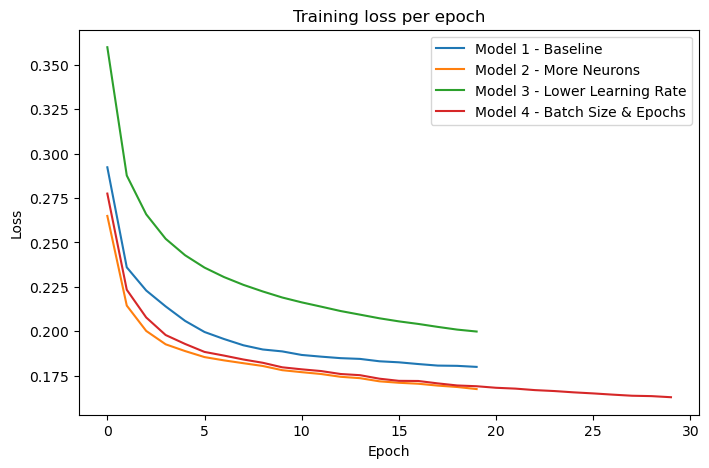

In [7]:
plt.figure(figsize=(8, 5))
for name, m in models.items():
    plt.plot(m.loss_curve_, label=name)
plt.title("Training loss per epoch")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend()
plt.show()

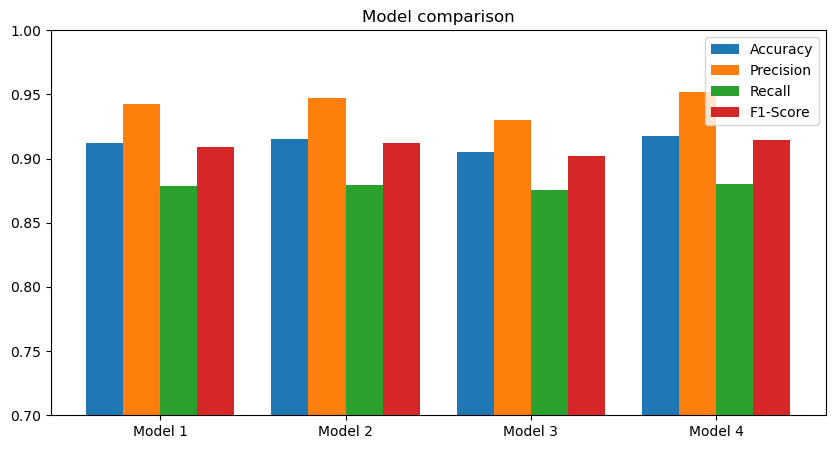

In [8]:
plt.figure(figsize=(10, 5))
x = np.arange(len(results)); width = 0.2
for i, col in enumerate(["Accuracy", "Precision", "Recall", "F1-Score"]):
    plt.bar(x + (i - 1.5) * width, results[col], width, label=col)
plt.xticks(x, [f"Model {i+1}" for i in range(len(results))])
plt.ylim(0.7, 1.0); plt.title("Model comparison"); plt.legend()
plt.show()

## 5. Best model – detailed evaluation

Best model: Model 4 - Batch Size & Epochs 



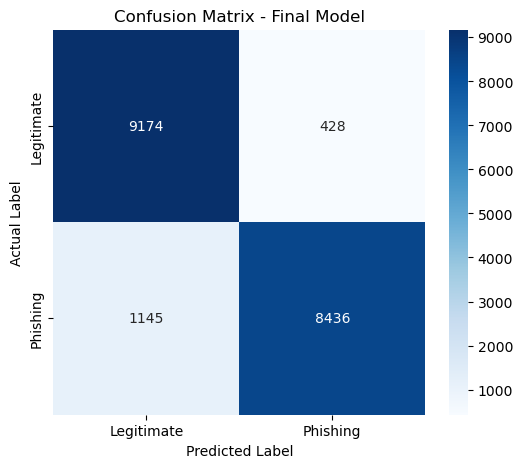

              precision    recall  f1-score   support

  Legitimate     0.8890    0.9554    0.9210      9602
    Phishing     0.9517    0.8805    0.9147      9581

    accuracy                         0.9180     19183
   macro avg     0.9204    0.9180    0.9179     19183
weighted avg     0.9203    0.9180    0.9179     19183



In [9]:
best_name = results.sort_values("F1-Score", ascending=False).iloc[0]["Model"]
final_model = models[best_name]
final_pred = final_model.predict(X_test)
print("Best model:", best_name, "\n")

cm = confusion_matrix(y_test, final_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Legitimate", "Phishing"], yticklabels=["Legitimate", "Phishing"])
plt.title("Confusion Matrix - Final Model")
plt.xlabel("Predicted Label"); plt.ylabel("Actual Label")
plt.show()

print(classification_report(y_test, final_pred, target_names=["Legitimate", "Phishing"], digits=4))

## 6. URL checker

`check_url()` takes any URL and returns a verdict. Well-known sites are matched by their **registered domain only**, so `paypal.com.evil.xyz` is still flagged.

In [10]:
TRUSTED = {"google.com", "youtube.com", "facebook.com", "amazon.com", "wikipedia.org",
           "microsoft.com", "apple.com", "github.com", "paypal.com", "netflix.com",
           "linkedin.com", "twitter.com", "x.com", "instagram.com", "yahoo.com",
           "bbc.co.uk", "stackoverflow.com", "reddit.com", "ebay.com", "openai.com",
           "anthropic.com", "claude.ai", "whatsapp.com", "zoom.us", "dropbox.com"}

def is_trusted(host):
    return any(host == d or host.endswith("." + d) for d in TRUSTED)

def check_url(url):
    host = parse(url)[0]
    if not url.strip() or "." not in host:
        return None
    prob = float(final_model.predict_proba(scaler.transform([extract_features(url)]))[0][1])
    trusted = is_trusted(host)
    if trusted:
        prob = min(prob, 0.05)
    return {"url": url, "host": host, "phishing_probability": prob,
            "verdict": "PHISHING" if prob >= 0.5 else "LEGITIMATE", "trusted": trusted}

tests = ["https://www.google.com", "https://github.com/anthropics", "https://www.bbc.co.uk/news",
         "http://paypal.com.secure-login.verify-account.info/webscr?cmd=_login",
         "http://192.168.4.12/bank/login.php", "http://amaz0n-support-confirm.top/signin?id=88123",
         "https://secure.paypal.com-account-update.xyz/login", "http://appleid-verify.tk/"]
for u in tests:
    r = check_url(u)
    print(f"{r['phishing_probability']*100:5.1f}%  {r['verdict']:10s}  {u}")

  0.2%  LEGITIMATE  https://www.google.com
  1.3%  LEGITIMATE  https://github.com/anthropics
  5.0%  LEGITIMATE  https://www.bbc.co.uk/news
100.0%  PHISHING    http://paypal.com.secure-login.verify-account.info/webscr?cmd=_login
100.0%  PHISHING    http://192.168.4.12/bank/login.php
100.0%  PHISHING    http://amaz0n-support-confirm.top/signin?id=88123
100.0%  PHISHING    https://secure.paypal.com-account-update.xyz/login
100.0%  PHISHING    http://appleid-verify.tk/


## 7. Frontend – type a URL and click **Check**

In [11]:
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

url_box = widgets.Text(placeholder="https://example.com/login", description="URL:",
                       layout=widgets.Layout(width="650px"))
btn = widgets.Button(description="Check URL", button_style="primary", icon="shield")
out = widgets.Output()

def on_click(_):
    with out:
        clear_output()
        r = check_url(url_box.value)
        if r is None:
            display(HTML("<p style='color:#b45309'>Please enter a valid URL, e.g. https://example.com</p>"))
            return
        bad = r["verdict"] == "PHISHING"
        color, bg, icon = ("#b91c1c", "#fee2e2", "⚠️") if bad else ("#15803d", "#dcfce7", "✅")
        pct = r["phishing_probability"] * 100
        note = " (well-known site)" if r["trusted"] else ""
        display(HTML(f"""
        <div style="background:{bg};color:{color};padding:16px;border-radius:10px;max-width:650px;font-family:sans-serif">
          <div style="font-size:20px;font-weight:700">{icon} {'Likely PHISHING' if bad else 'Looks LEGITIMATE'}</div>
          <div style="margin:8px 0">Domain: <b>{r['host']}</b>{note}</div>
          <div style="background:#e5e7eb;border-radius:6px;height:10px;overflow:hidden">
            <div style="width:{pct:.1f}%;height:10px;background:{color}"></div></div>
          <div style="margin-top:6px">Phishing probability: <b>{pct:.1f}%</b></div>
        </div>"""))

btn.on_click(on_click)
url_box.on_submit(on_click)
display(widgets.HBox([url_box, btn]), out)

Output()

### No widgets? Use this simple version instead

If the box above does not show up, run this cell and type a URL when asked.

In [12]:
# url = input("Enter a URL: ")
# r = check_url(url)
# print(r["verdict"], f"({r['phishing_probability']*100:.1f}% phishing)")

## 8. Limitations

- The dataset is old (many 2012-era phishing pages), so modern lookalike URLs can be missed.
- The model only looks at the URL text – it never opens the page or checks domain reputation/age.
- The trusted-site list is short and hand-written.
- A prediction is not a guarantee – don't rely on it alone.